# 第一个可训练量子电路

只使用一个量子比特、一个 RY 门和一个角度参数。目标是调整角度，让 Z 测量的期望值接近 **0.5**。

训练仍然使用熟悉的 `nn.MSE()`、`loss.backward()` 和 `nn.SGD(...)`。这里严格更新两次参数，先验证完整流程；两步后不要求已经达到目标。


In [1]:
from math import cos

from qutai import Tensor, nn, quantum as qu, visualization as vis


## 1. 一个可以学习的旋转角度

`requires_grad=True` 表示我们希望学习这个角度。电路保存参数引用，每次执行都会读取更新后的角度，再生成对应的旋转矩阵。

`circuit.run()` 返回量子态；`circuit.expectation(...)` 返回测量期望值。画图只读取门和参数，不执行训练。


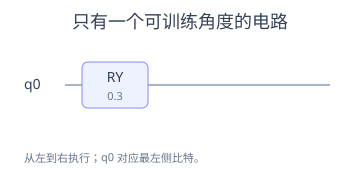

In [2]:
angle = Tensor(0.3, requires_grad=True)
circuit = qu.Circuit(1, [qu.RY(0, angle)])
observable = qu.Z(0)
target = 0.5

vis.Circuit(circuit, title="只有一个可训练角度的电路")


## 2. 期望值是怎么来的

Z 测量将结果 0 记为 +1，将结果 1 记为 −1，因此：

$$\langle Z\rangle=P(0)-P(1).$$

初始态经过 RY 后，振幅为 `cos(angle / 2)` 和 `sin(angle / 2)`，所以这个电路的期望值正好是 `cos(angle)`。
这里从模拟器直接计算理论期望值，不需要采样；训练结果也不会受到采样随机性的影响。


初始角度: 0.3
初始期望值: 0.9553364891256059
目标期望值: 0.5


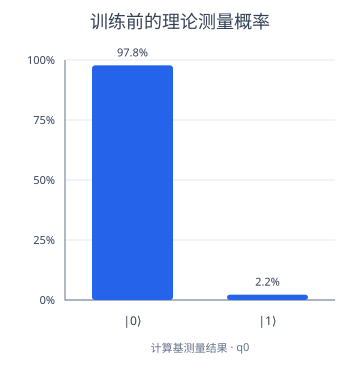

In [3]:
prediction = circuit.expectation(observable)
print("初始角度:", angle.item())
print("初始期望值:", prediction.item())
print("目标期望值:", target)

vis.Probabilities(circuit.run(), title="训练前的理论测量概率")


## 3. 损失函数和优化器沿用现有接口

`nn.SGD(circuit, ...)` 自动收集电路的可训练参数，不用手动传参数列表。均方误差衡量期望值距离目标还有多远。

我们保存训练前以及每次参数更新后的角度、预测值和损失，方便最后对照。


In [4]:
optimizer = nn.SGD(circuit, learning_rate=0.5)
loss_function = nn.MSE()
initial_loss = loss_function(prediction, target).item()
history = [[0, angle.item(), prediction.item(), initial_loss]]

print("训练前 MSE:", initial_loss)


训练前 MSE: 0.207331318329233


## 4. 更新两次参数

每一步仍然是：清除旧梯度 → 前向与损失 → 反向传播 → 更新参数。

量子部分默认用伴随求导计算局部梯度，再交回同一套自动求导引擎；也可以在 expectation 中指定 method="parameter-shift" 对照。对这里的单个 RY 门，期望值关于角度的导数为 `-sin(angle)`；损失对角度的梯度还会乘上 MSE 传来的那部分。

打印的梯度对应更新前的角度；表格记录的是更新后的结果。


In [5]:
for step in range(1, 3):
    optimizer.zero_grad()
    prediction = circuit.expectation(observable)
    loss = loss_function(prediction, target)
    loss.backward()
    gradient = angle.grad.item()
    optimizer.step()

    prediction = circuit.expectation(observable)
    current_loss = loss_function(prediction, target).item()
    history.append([step, angle.item(), prediction.item(), current_loss])
    print(f"step {step}  gradient {gradient:.6f}  angle {angle.item():.6f}  MSE {current_loss:.6f}")

vis.Table(history, columns=["更新次数", "角度", "Z 期望值", "MSE"], title="两次更新的完整记录")


step 1  gradient -0.269122  angle 0.434561  MSE 0.165694
step 2  gradient -0.342750  angle 0.605936  MSE 0.103664


更新次数,角度,Z 期望值,MSE
0,0.3,0.9553364891256059,0.207331318329233
1,0.4345611333668479,0.907054897924061,0.16569368992396774
2,0.6059362789501387,0.8219692172403869,0.10366417685038742


## 5. 看损失如何变化

横坐标 0 是训练前，1 和 2 是对应次数参数更新后的损失。这里只有两步，重点是确认梯度和参数更新已经接通。


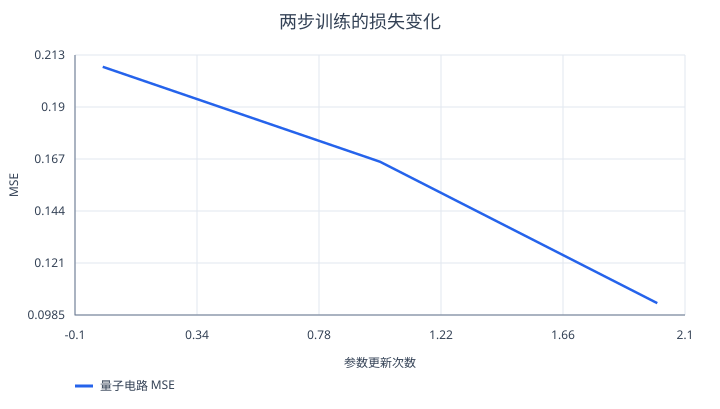

In [6]:
vis.Plot(title="两步训练的损失变化", xlabel="参数更新次数", ylabel="MSE").line(
    [row[0] for row in history], [row[3] for row in history], label="量子电路 MSE"
)


## 6. 更新后的电路输出

电路仍是同一个对象，角度已由 SGD 更新。我们比较模拟结果与 `cos(angle)`，再看更新后的概率分布。

量子态的振幅继续使用复数；训练参数、期望值和损失使用实数 Tensor。这个例子把它们连接了起来，没有另建一套反向引擎。


更新后的角度: 0.6059362789501387
电路计算的期望值: 0.8219692172403869
cos(angle): 0.8219692172403867
MSE: 0.10366417685038742


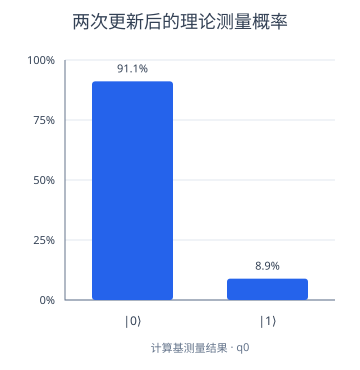

In [7]:
print("更新后的角度:", angle.item())
print("电路计算的期望值:", prediction.item())
print("cos(angle):", cos(angle.item()))
print("MSE:", history[-1][3])

vis.Probabilities(circuit.run(), title="两次更新后的理论测量概率")
